In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import sympy as sp
from scipy.optimize import curve_fit
from scipy.optimize import fsolve
from scipy import integrate
from functions import Euler_Burgers
from functions import ShockTime_Burgers

In [2]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Numerically solving the equation:

$$ u_t + uu_x = 0$$
where now $ v = u(x, t) $.

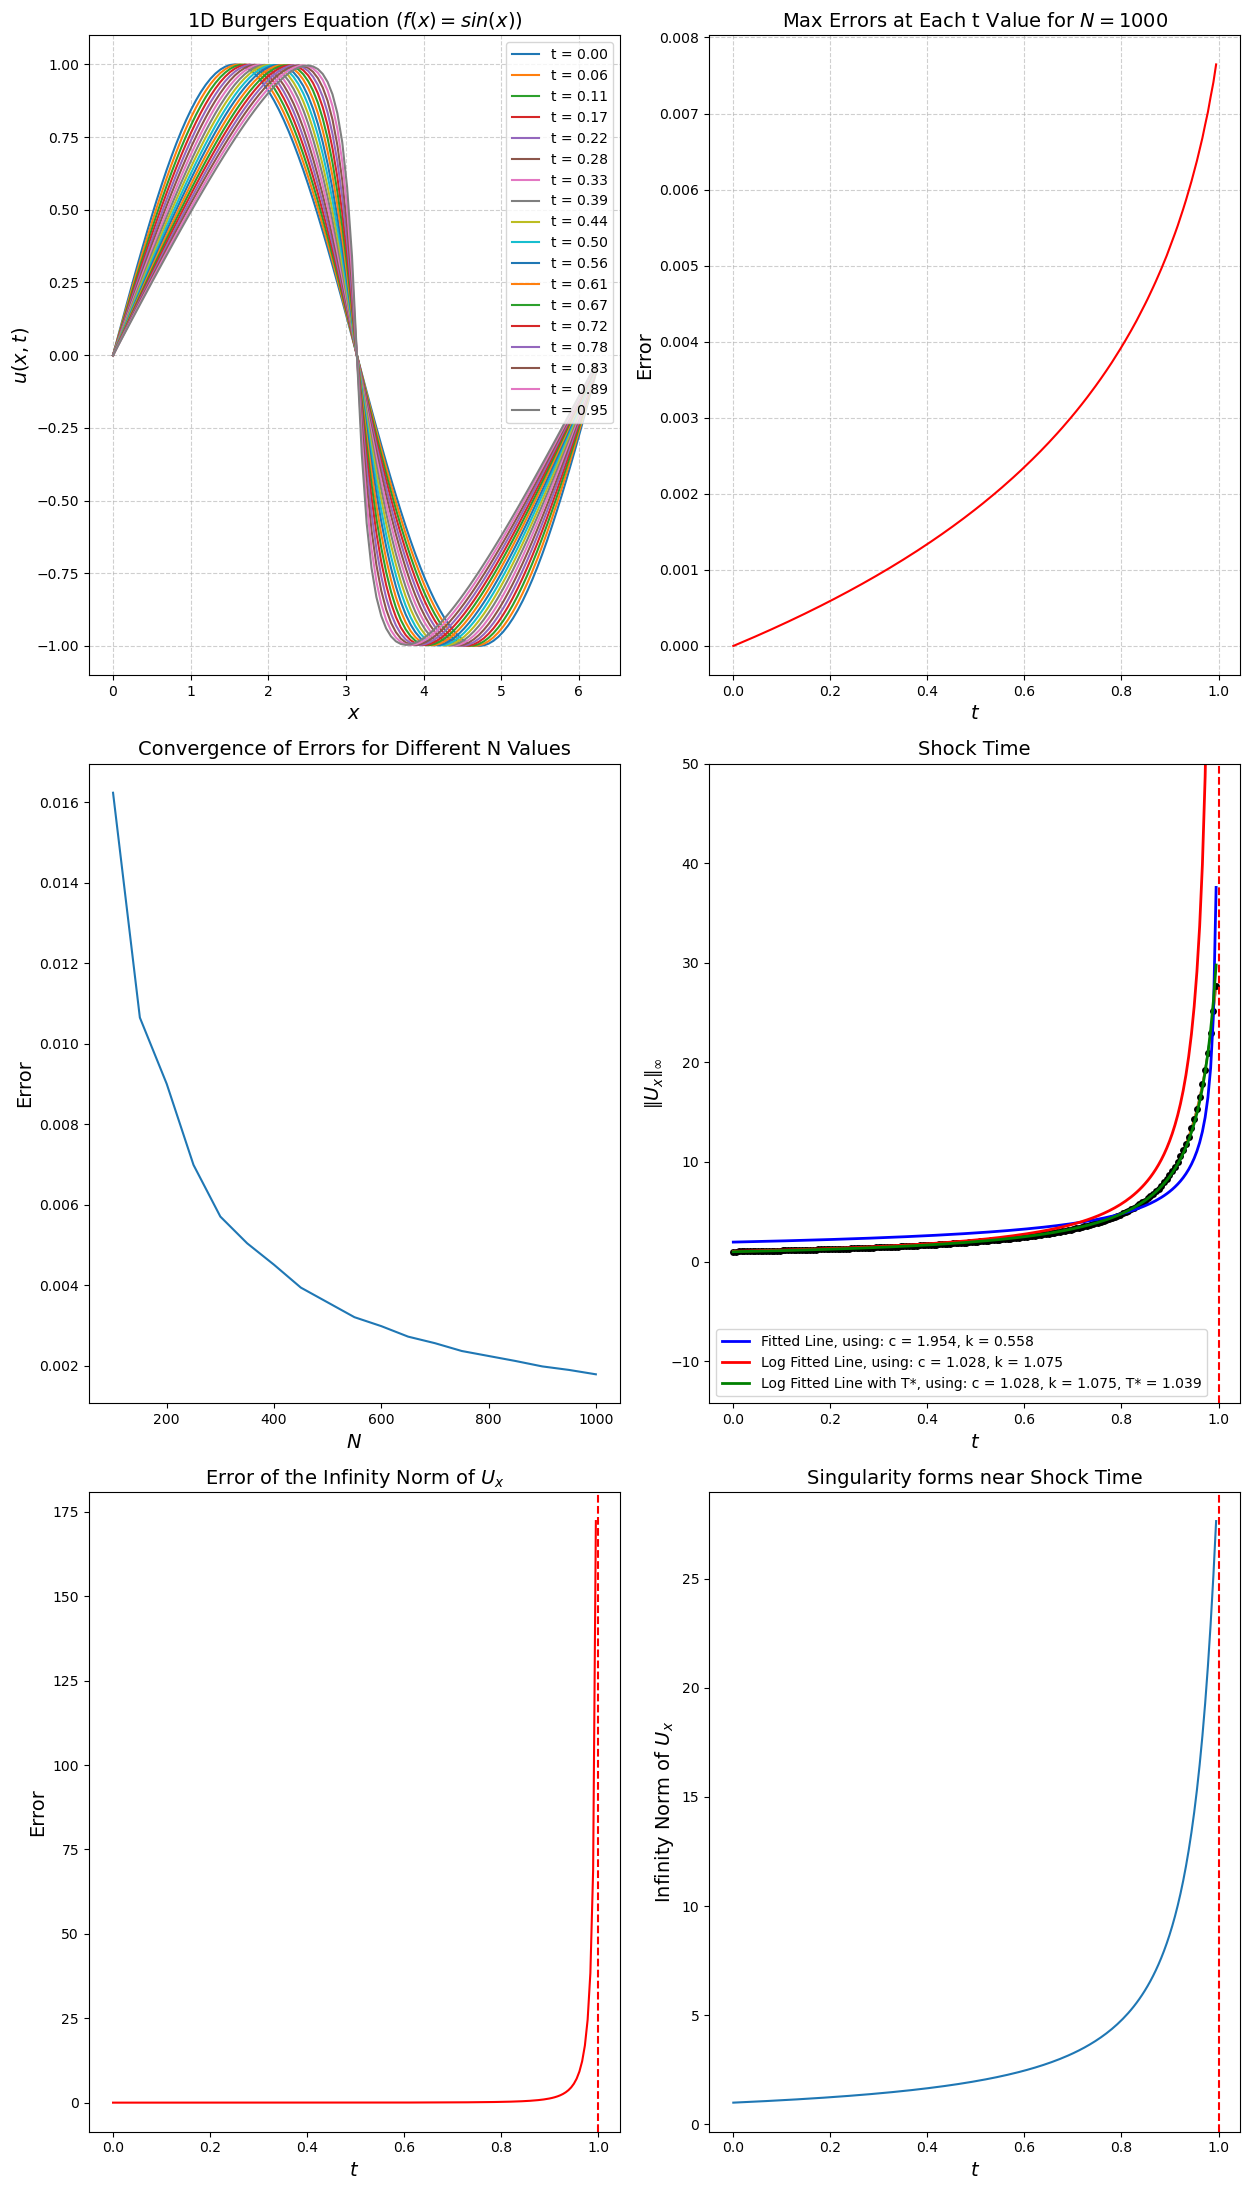

In [8]:
# Initial Condition 3:

# Set up x points
L = 2*np.pi
N = np.linspace(100, 1000, 19).astype(int)
x = np.linspace(0, L, N[0], endpoint = False)

# IC for u is a sine wave
u0 = np.sin(x)

# Time discretization (CFL condition)
t_start = 0.0
t_end = ShockTime_Burgers(x, u0)
CFL = 0.9
delta_x = L / N[0]
delta_t = CFL * delta_x / np.max(np.abs(u0))
num_steps = int(np.round((t_end - t_start) / delta_t))
t = np.linspace(t_start, t_end, num_steps, endpoint=False)


# Solve PDE
u = Euler_Burgers(u0, t, x)

# Error
u_exact = np.sin(x[None, :] - u * t[:, None])
error = np.abs(u-u_exact)
max_errors = np.max(error, axis=1)
Linf = np.max(error)

# Step Size Analysis
u_list = []
mid_errors = []
new_max_errors = []
for i in range(len(N)):
    new_x = np.linspace(0, L, N[i], endpoint = False)
    new_u0 = np.sin(new_x)
    delta_x = L / N[i]
    delta_t = CFL * delta_x / np.max(np.abs(new_u0))
    num_steps = int(np.round((t_end - t_start) / delta_t))
    new_t = np.linspace(t_start, t_end, num_steps, endpoint=False)
    u_el = Euler_Burgers(new_u0, new_t, new_x)
    u_exact = np.sin(new_x[None, :] - u_el * new_t[:, None])
    error = np.abs(u_el-u_exact)
    t_target = 0.5 * t_end
    idx = np.argmin(np.abs(new_t - t_target))
    mid_errors.append(np.max(error[idx]))
    new_max_errors.append(np.max(error))
max_errors = np.max(error, axis = 1)

# Gradient Analysis
dx = new_x[1] - new_x[0]
du_dx = np.gradient(u_el, dx, axis=1)

def interp(x0,x1,x2,x):
    return (x0[1]*(x-x1[0])*(x-x2[0])/((x0[0]-x1[0])*(x0[0]-x2[0])) +
            x1[1]*(x-x2[0])*(x-x0[0])/((x1[0]-x2[0])*(x1[0]-x0[0])) +
            x2[1]*(x-x0[0])*(x-x1[0])/((x2[0]-x0[0])*(x2[0]-x1[0])))
                        
# Function to interpolate gradient to find accurate maximum
def interpdiv(x0,x1,x2):
    return -((x0[0] + x2[0])*x1[1]*(x2[0] - x0[0]) - (x1[0] + x2[0])*x0[1]*(x2[0] - x1[0]) - (x0[0] + x1[0])*x2[1]*(x1[0] - x0[0])) / (2 * (x0[1] * (x2[0] - x1[0]) - x1[1] * (x2[0] - x0[0]) + x2[1] * (x1[0] - x0[0])))

ind_max_abs_du_dx = np.argmax(np.abs(du_dx), axis=1)
ind_max_abs_du_dx[0] = ind_max_abs_du_dx[1]
max_abs_du_dx = np.max(np.abs(du_dx), axis=1)
points_to_int = np.zeros((len(new_t), 3, 2)) 
interp_x = []
new_du_dx = np.zeros((len(new_t), 100))
int_max_abs_du_dx = np.zeros(len(new_t))

for i in range(len(ind_max_abs_du_dx)):
    xi = new_x[ind_max_abs_du_dx[i]-1 : ind_max_abs_du_dx[i]+2]
    yi = du_dx[i, ind_max_abs_du_dx[i]-1 : ind_max_abs_du_dx[i]+2]
    # Store the absolute value of the maximum gradient magnitude
    x_pos = interpdiv([xi[0],yi[0]], [xi[1],yi[1]], [xi[2],yi[2]])
    int_max_abs_du_dx[i] = abs(interp([xi[0],yi[0]], [xi[1],yi[1]], [xi[2],yi[2]], x_pos))

T_star = ShockTime_Burgers(new_x, new_u0)
t_limit = new_t[new_t < T_star]
def fitted_model(t, c, k):
    return c / (T_star - t)**k
popt, pcov = curve_fit(fitted_model, t_limit, max_abs_du_dx[:len(t_limit)], p0=(1,1))  # p0 is the initial guesses
c_fit, k_fit = popt
def log_fitted_model(t, c, k):
    return np.log(c) - k * np.log(T_star - t)
log_popt, log_pcov = curve_fit(log_fitted_model, t_limit, np.log(int_max_abs_du_dx[:len(t_limit)]), p0=(2,1))  # p0 is the initial guesses
log_c_fit, log_k_fit = log_popt
def log_fitted_model_with_T(t, c, k, T):
    return np.log(c) - k * np.log(T - t)
log_T_popt, log_T_pcov = curve_fit(log_fitted_model_with_T, t_limit, np.log(int_max_abs_du_dx[:len(t_limit)]), p0=(1,1, 1))  # p0 is the initial guesses
log_c_fit, log_k_fit, log_T_fit = log_T_popt

# Exact values for u
exact_du_dx = 1 / (T_star - new_t) 

# Plot results
fig, ((ax1, ax2), (ax3, ax4), (ax5, ax6)) = plt.subplots(3, 2, figsize=(13, 22))
for i in range(0, len(t), len(t)//10):   # plot ~10 snapshots
    ax1.plot(x, u[i], label=f"t = {t[i]:.2f}")
ax1.set_title(r"1D Burgers Equation $(f(x) = sin(x))$", fontsize=14)
ax1.set_xlabel(r"$x$", fontsize=14)
ax1.set_ylabel(r"$u(x,t)$", fontsize=14)
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.6)

ax2.plot(new_t, max_errors, color='r')
ax2.set_title(r"Max Errors at Each t Value for $N = 1000$", fontsize=14)
ax2.set_xlabel(r"$t$", fontsize=14)
ax2.set_ylabel("Error", fontsize=14)
ax2.grid(True, linestyle="--", alpha=0.6)

ax3.plot(N, mid_errors)
ax3.set_title("Convergence of Errors for Different N Values", fontsize=14)
ax3.set_xlabel(r"$N$", fontsize=14)
ax3.set_ylabel("Error", fontsize=14)

ax4.plot(t_limit, int_max_abs_du_dx[:len(t_limit)])
ax4.plot(t_limit, int_max_abs_du_dx[:len(t_limit)], marker='.', markersize=10, markerfacecolor='black', markeredgewidth=0)
ax4.plot(t_limit, fitted_model(t_limit, c_fit, k_fit), 'blue', label=f'Fitted Line, using: c = {round(c_fit, 3)}, k = {round(k_fit, 3)}', linewidth=2)
ax4.plot(t_limit, np.exp(log_fitted_model(t_limit, log_c_fit, log_k_fit)), 'red', label=f'Log Fitted Line, using: c = {round(log_c_fit, 3)}, k = {round(log_k_fit, 3)}', linewidth=2)
ax4.plot(t_limit, np.exp(log_fitted_model_with_T(t_limit, log_c_fit, log_k_fit, log_T_fit)), 'green', label=f'Log Fitted Line with T*, using: c = {round(log_c_fit, 3)}, k = {round(log_k_fit, 3)}, T* = {round(log_T_fit, 3)}', linewidth=2)
ax4.axvline(x=T_star, color='r', linestyle='--', linewidth=1.5)
ax4.set_ylim(top=50)
ax4.set_title("Shock Time", fontsize=14)
ax4.set_xlabel(r"$t$", fontsize=14)
ax4.set_ylabel(r"$\left\| U_x \right\|_{\infty}$", fontsize=14)
ax4.legend()

#ax5.plot(t_limit, abs(exact_du_dx[:len(t_limit)] - int_max_abs_du_dx[:len(t_limit)]), color = 'blue')
ax5.plot(t_limit, abs(exact_du_dx[:len(t_limit)] - int_max_abs_du_dx[:len(t_limit)]), color = 'red')
ax5.axvline(x=T_star, color='r', linestyle='--', linewidth=1.5)
ax5.set_title(r"Error of the Infinity Norm of $U_x$", fontsize=14)
ax5.set_xlabel(r"$t$", fontsize=14)
ax5.set_ylabel("Error", fontsize=14)

ax6.plot(t_limit, int_max_abs_du_dx[:len(t_limit)])
ax6.axvline(x=T_star, color='r', linestyle='--', linewidth=1.5)
ax6.set_title("Singularity forms near Shock Time", fontsize=14)
ax6.set_xlabel(r"$t$", fontsize=14)
ax6.set_ylabel(r"Infinity Norm of $U_x$", fontsize=14)

plt.tight_layout()
plt.savefig("IC3.jpg")
#plt.show()
burgers_t_values = t_limit[t_limit < 0.98]
burgers_du_error = ((abs(exact_du_dx[:len(t_limit)] - int_max_abs_du_dx[:len(t_limit)]))/(abs(exact_du_dx[:len(t_limit)] + int_max_abs_du_dx[:len(t_limit)])))[:len(burgers_t_values)]

In [5]:
%%capture

fig, ax = plt.subplots(figsize=(8,5))
line, = ax.plot(x, u[0], lw=2)
#ax.set_title("Animated 1D Linear Advection (Upwind Scheme)")
ax.set_xlabel("x")
ax.set_ylabel("u(x,t)")
plt.grid(True, linestyle="--", alpha=0.6)
time_text = ax.text(0.02, 0.9, '', transform=ax.transAxes)

# Update function for animation
def update(frame):
    line.set_ydata(u[frame])
    time_text.set_text(f"t = {t[frame]:.2f}")
    return line, time_text

# Make animation
ani = FuncAnimation(fig, update, frames=len(t), interval=50, blit = True)

plt.show()

In [6]:
HTML(ani.to_html5_video())

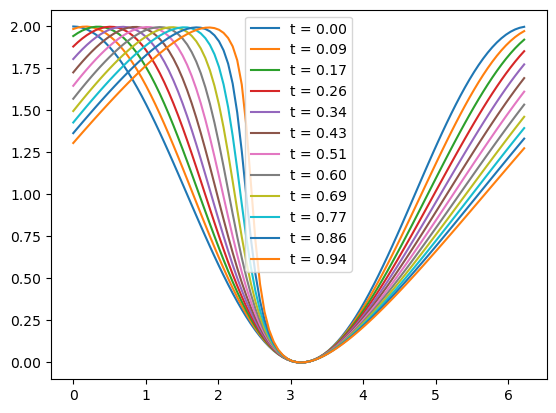

In [7]:
# Set up x points
L = 2*np.pi
N = np.linspace(100, 1000, 19).astype(int)
x = np.linspace(0, L, N[0], endpoint = False)

# IC for u is a sine wave
u0 = 1+np.cos(x)

# Time discretization (CFL condition)
t_start = 0.0
t_end = ShockTime_Burgers(x, u0)
CFL = 0.9
delta_x = L / N[0]
delta_t = CFL * delta_x / np.max(np.abs(u0))
num_steps = int(np.round((t_end - t_start) / delta_t))
t = np.linspace(t_start, t_end, num_steps, endpoint=False)


# Solve PDE
u = Euler_Burgers(u0, t, x)

for i in range(0, len(t), len(t)//10):   # plot ~10 snapshots
    plt.plot(x, u[i], label=f"t = {t[i]:.2f}")
#ax1.set_title("1D Burgers Equation (Upwind Euler Scheme)")
#ax1.set_xlabel("x")
#ax1.set_ylabel("u(x,t)")
#ax1.legend()
#ax1.grid(True, linestyle="--", alpha=0.6)
plt.legend()

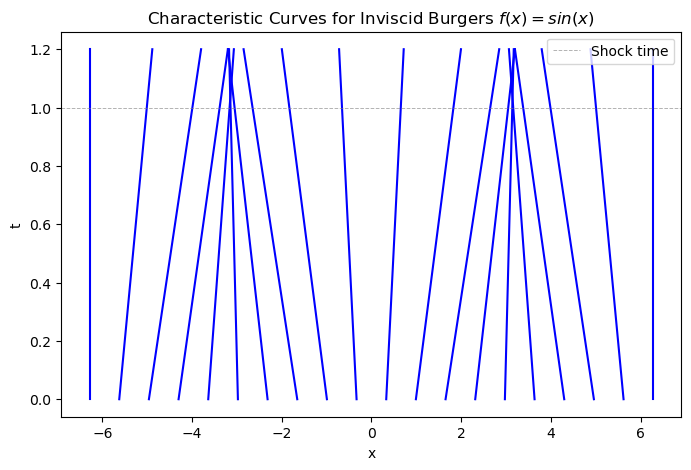

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Set up figure
plt.figure(figsize=(8,5))

# Domain
t = np.linspace(0, 1.2, 200)

# Left region: parallel characteristics
#x0_left = np.linspace(-2, -0.5, 10)
#for xi in x0_left:
    #x = xi + 1.0 * t   # constant speed (linear region)
    #plt.plot(x, t)

# Right region: converging characteristics (shock formation)
x0_right = np.linspace(-2*np.pi, 2*np.pi, 20)
def u0(x):
    return np.sin(x)  # causes convergence

for xi in x0_right:
    x = xi + u0(xi) * t
    plt.plot(x, t, color = 'b')

# Shock line
#t_shock = np.linspace(0.8, 1.2, 50)
#x_shock = 0.2 + 0.8*(t_shock - 0.8)
#plt.plot(x_shock, t_shock)
plt.axhline(1.0, color='gray', lw=0.7, ls='--', alpha=0.6, label = 'Shock time')
# Axes
plt.title(r"Characteristic Curves for Inviscid Burgers $f(x)=sin(x)$")
plt.xlabel("x")
plt.ylabel("t")

# Clean look (no grid, minimal styling)
#plt.xlim(-2.5, 2.5)
#plt.ylim(0, 1.2)
plt.legend()
plt.show()